Placement through one transform: rotate, scale, flip and place, plus boolean cut-outs.

A ring of petals is built from one shape by rotating copies about a shared pivot, then cut and clipped.
Run it as ``python transforms.py [OUTPUT_DIR]`` or open ``transforms.ipynb`` to see each step.

In [1]:
import sys
import tempfile
from pathlib import Path

import svgwriter as svg

Every shape carries one transform. `rotate(angle, about=pivot)` edits it, so copies of a petal
turned about the centre make a ring.

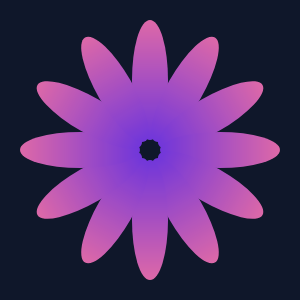

In [2]:
SIZE = 300
CENTER = (SIZE / 2, SIZE / 2)
PETALS = 12

doc = svg.Document(SIZE, SIZE)
doc.rect(0, 0, SIZE, SIZE, fill="#0f172a")

petal = svg.ellipse(SIZE / 2, SIZE / 2 - 70, 18, 60, fill=svg.LinearGradient.vertical("#f472b6", "#7c3aed"))
with doc.group(opacity=0.9):
    for i in range(PETALS):
        doc.add(petal @ 0).rotate(360 * i / PETALS, about=CENTER)
doc

Subtracting one shape from another (`-`) gives a path with a cut-out: a disc minus a star.

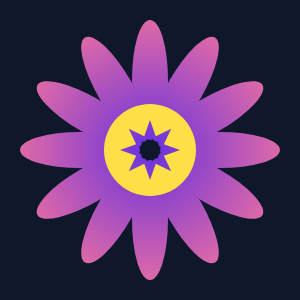

In [3]:
core = svg.circle(*CENTER, 46) - svg.builder.star(*CENTER, 30, points=8)
doc += core.update(fill="#fde047")
doc

`place(x, y)` moves a shape's origin, which suits shapes built around (0, 0).

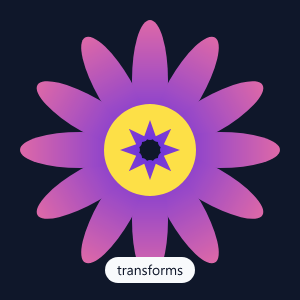

In [4]:
badge = svg.rect.from_center((0, 0), (90, 26), rx=13, fill="#f8fafc")
doc += badge.place(SIZE / 2, SIZE - 30)
doc.text("transforms", x=SIZE / 2, y=SIZE - 25, font_size=14, text_anchor="middle", fill="#0f172a")
doc

`flip_x` and `flip_y` mirror a clone about a point: one arrow becomes four corners.

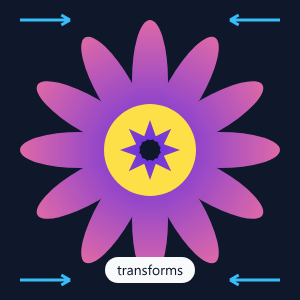

In [5]:
corner = svg.builder.arrow(20, 20, 70, 20, head=10, stroke="#38bdf8", stroke_width=3)
doc += [corner, corner.clone().flip_x(about=CENTER), corner.clone().flip_y(about=CENTER),
        corner.clone().flip_x(about=CENTER).flip_y(about=CENTER)]
doc

`clip` intersects a shape with another: a square clipped by a circle is a round frame.

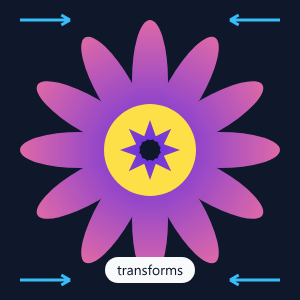

In [6]:
window = svg.rect(0, 0, SIZE, SIZE).clip(svg.circle(*CENTER, SIZE / 2 - 4))
window.update(fill="none", stroke="#334155", stroke_width=8)
doc += window
doc

Save SVG and a 2x PNG. Pass a folder as the first argument to choose where they go.

In [7]:
args = sys.argv[1:2]
out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
doc.save(out / "transforms.svg")
doc.save(out / "transforms.png", scale=2)
print("saved transforms.svg and transforms.png")

saved transforms.svg and transforms.png
